### Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. Frequency Tables:

- Generate a frequency table for the product category.
- Which are the top 5 most listed product categories?

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 

In [7]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\mocim\OneDrive\Desktop\Lessons\Week 5_EDA_Inferencial_Statistics
['.ipynb_checkpoints', '1.EDA_univariate.ipynb', 'Lab EDA.ipynb', 'lab-eda-univariate_1']


In [8]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [9]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [10]:
df.shape

(2443651, 9)

In [11]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [15]:
# the most popular category 

df["category"].mode()[0]

'Sports & Outdoors'

In [40]:
table_categories = df["category"].value_counts()
table_categories.sort_values(ascending = False)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [41]:
type(table_categories)

pandas.core.series.Series

In [49]:
table = pd.crosstab(index = df["category"], columns = "count")
table.sort_values("count", ascending = False).head(5)


col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


In [46]:
table.columns

Index(['count'], dtype='object', name='col_0')

### 2. Visualizations:

- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [60]:
table_top = table.sort_values("count", ascending = False).head(10)
table_top 

col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
Manicure & Pedicure Products,18940
Skin Care,18769
Make-up,18756
Hair Care,18735


<Axes: xlabel='category'>

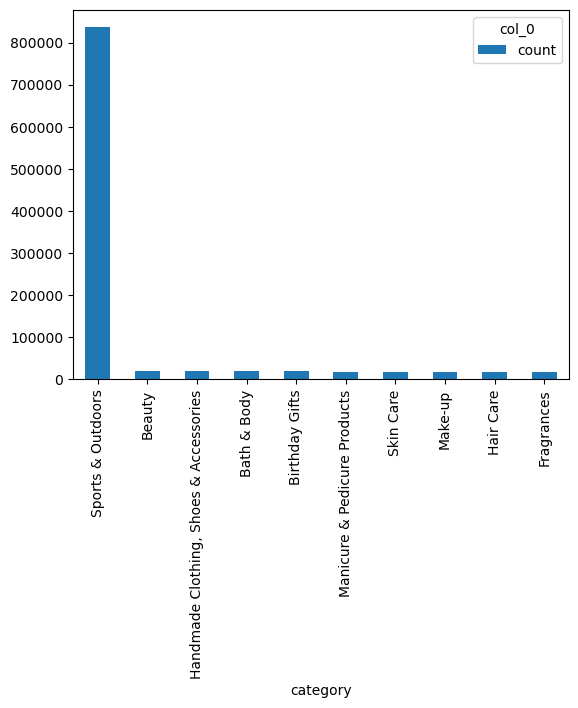

In [54]:
table_top.plot(kind = "bar")
plt.title 

In [61]:
table_top2 = table.sort_values("count", ascending = False).reset_index().head(10)
table_top2 

col_0,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
5,Manicure & Pedicure Products,18940
6,Skin Care,18769
7,Make-up,18756
8,Hair Care,18735
9,Fragrances,18564


<Axes: ylabel='count'>

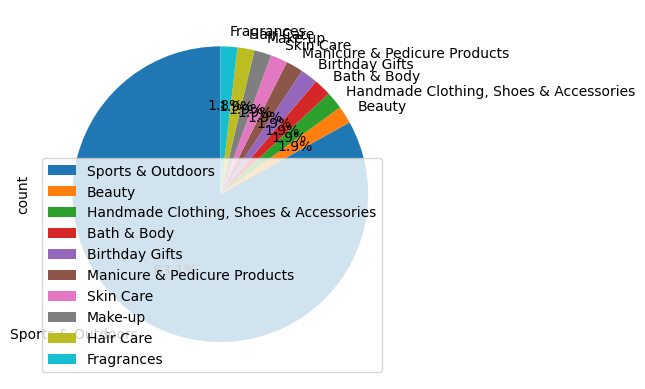

In [67]:
table_top.plot.pie(y="count", autopct='%1.1f%%', startangle=90)

### 3. Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [68]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


<Axes: xlabel='price', ylabel='Count'>

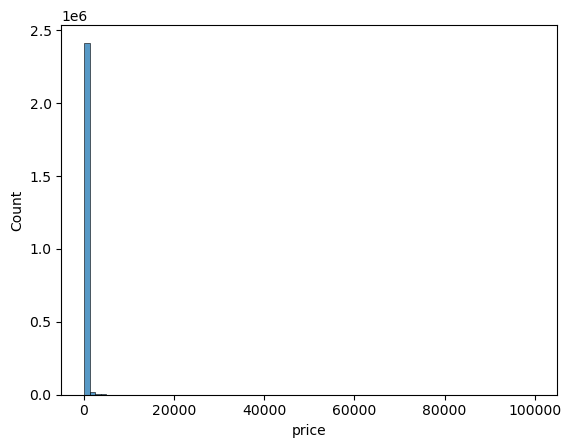

In [80]:
sns.histplot(df["price"], bins = 80)

<Axes: ylabel='price'>

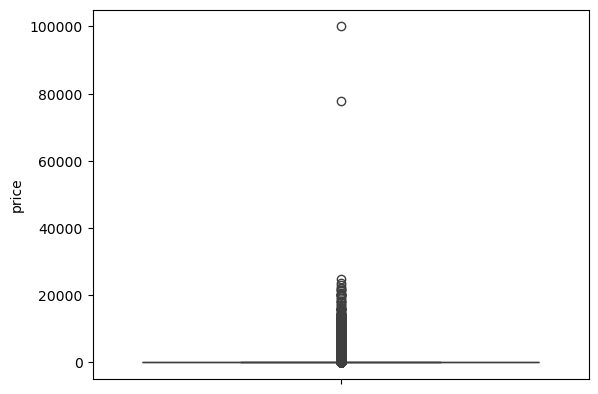

In [74]:
sns.boxplot(data = df["price"])

The data is extremely spread. There are several products which prices are extremely higher than the mean. 

The most of the prices fall between 0 - 2000 dollars. 

In [91]:
price_counts = df["price"].value_counts()
price_counts.sort_values(ascending = False).tail(50)

price
772.48     1
1960.20    1
280.44     1
2567.99    1
1094.36    1
623.19     1
584.39     1
3130.99    1
1013.75    1
891.88     1
612.27     1
312.05     1
3711.90    1
195.65     1
3745.00    1
984.37     1
1445.98    1
410.38     1
605.40     1
1630.80    1
481.68     1
516.90     1
647.40     1
425.32     1
618.46     1
498.13     1
416.74     1
506.52     1
268.38     1
468.72     1
449.01     1
566.57     1
627.59     1
431.53     1
4578.48    1
886.49     1
591.87     1
348.60     1
446.51     1
188.83     1
7999.99    1
1433.36    1
708.10     1
3038.28    1
521.53     1
481.17     1
560.60     1
1552.17    1
349.08     1
317.34     1
Name: count, dtype: int64

### 1. Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

In [95]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [111]:
df["stars"].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [105]:
df["stars"].mode() 

0    0.0
Name: stars, dtype: float64

The most frequent rating is 0 stars. It's a positive skewed distribution. At least half of the customers in the df has rated 0. 

### 2. Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?


In [108]:
df["stars"].std()

2.1948653785054697

In [109]:
df["stars"].var()

4.81743402976196

In [114]:
# Interquartile range = Q3 - Q1 

df["stars"].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [116]:
# IQR 

IQR = df["stars"].describe()[6] - df["stars"].describe()[4]
IQR

C:\Users\mocim\AppData\Local\Temp\ipykernel_22100\3426179089.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  IQR = df["stars"].describe()[6] - df["stars"].describe()[4]
C:\Users\mocim\AppData\Local\Temp\ipykernel_22100\3426179089.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  IQR = df["stars"].describe()[6] - df["stars"].describe()[4]


np.float64(4.4)

In [119]:
df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

np.float64(4.4)

<Axes: ylabel='stars'>

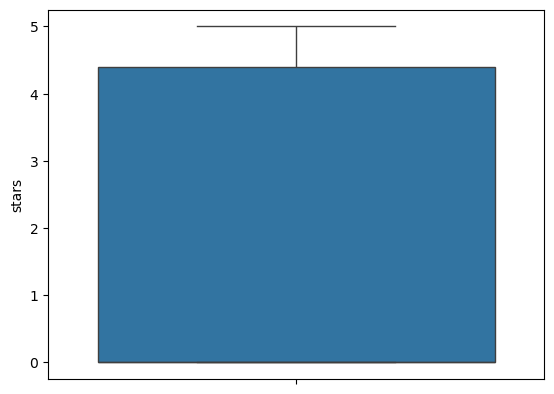

In [117]:
sns.boxplot(data = df["stars"])

There is a wide range of ratings. It's a positive skewed distribution. At least half of the customers in the df has rated 0. 
The IQR has a high value, means that dataset has a high variability. 

### 3. Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [120]:
# Positive skew, shows right skewed. The tail in the right side is longer than the left one. 

df["stars"].skew()

np.float64(0.08120735761080881)

In [121]:
# Negative kurtosis means flatter distribution and lighter tails. 

df["stars"].kurtosis()

np.float64(-1.9260061280432994)

### 4. Visualizations:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

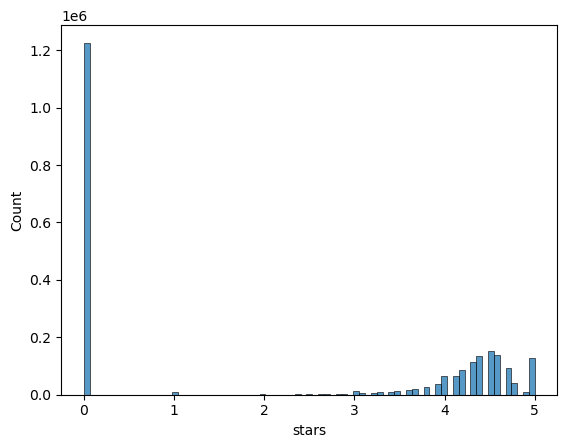

In [122]:
sns.histplot(df["stars"])

The most frequent rating is 0. 